In [ ]:

#!pip install -q transformers datasets torch nltk networkx scikit-learn rouge-score pandas matplotlib tqdm accelerate


In [ ]:

import torch
import transformers
import datasets
import nltk
import networkx
import sklearn
import pandas as pd

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch: 2.11.0+cu130
Transformers: 4.46.3
Datasets: 4.8.5
GPU Available: True
GPU: Tesla T4


In [ ]:

import re
import os
import numpy as np
import pandas as pd
import nltk
import networkx as nx
import torch

from nltk.tokenize import sent_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer
from datasets import load_dataset
from transformers import pipeline
from rouge_score import rouge_scorer
from tqdm.auto import tqdm

nltk.download("punkt")
nltk.download("punkt_tab")

print("All libraries imported successfully!")


All libraries imported successfully!


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [ ]:

dataset = load_dataset(
    "abisee/cnn_dailymail",
    "3.0.0",
    split={
        "train": "train[:500]",
        "validation": "validation[:100]",
        "test": "test[:100]"
    }
)

train_data = dataset["train"]
validation_data = dataset["validation"]
test_data = dataset["test"]

print("Training records:", len(train_data))
print("Validation records:", len(validation_data))
print("Testing records:", len(test_data))


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Training records: 500
Validation records: 100
Testing records: 100


In [ ]:

sample = train_data[0]

print("ARTICLE:")
print(sample["article"][:1000])

print("\nREFERENCE SUMMARY:")
print(sample["highlights"])


ARTICLE:
LONDON, England (Reuters) -- Harry Potter star Daniel Radcliffe gains access to a reported £20 million ($41.1 million) fortune as he turns 18 on Monday, but he insists the money won't cast a spell on him. Daniel Radcliffe as Harry Potter in "Harry Potter and the Order of the Phoenix" To the disappointment of gossip columnists around the world, the young actor says he has no plans to fritter his cash away on fast cars, drink and celebrity parties. "I don't plan to be one of those people who, as soon as they turn 18, suddenly buy themselves a massive sports car collection or something similar," he told an Australian interviewer earlier this month. "I don't think I'll be particularly extravagant. "The things I like buying are things that cost about 10 pounds -- books and CDs and DVDs." At 18, Radcliffe will be able to gamble in a casino, buy a drink in a pub or see the horror film "Hostel: Part II," currently six places below his number one movie on the UK box office chart. Detai

In [ ]:

for split_name, split_data in dataset.items():
    empty_articles = sum(
        1 for x in split_data
        if not x["article"].strip()
    )

    empty_summaries = sum(
        1 for x in split_data
        if not x["highlights"].strip()
    )

    print(
        split_name,
        "Empty articles:", empty_articles,
        "Empty summaries:", empty_summaries
    )


train Empty articles: 0 Empty summaries: 0
validation Empty articles: 0 Empty summaries: 0
test Empty articles: 0 Empty summaries: 0


In [ ]:

def clean_text(text):
    text = str(text)

    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text)

    return text.strip()


def preprocess_dataset(data):
    records = []

    for item in data:
        article = clean_text(item["article"])
        summary = clean_text(item["highlights"])

        if article and summary:
            records.append({
                "article": article,
                "reference": summary
            })

    return pd.DataFrame(records)


train_df = preprocess_dataset(train_data)
val_df = preprocess_dataset(validation_data)
test_df = preprocess_dataset(test_data)

print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)


Training: (500, 2)
Validation: (100, 2)
Testing: (100, 2)


In [ ]:

def textrank_summarizer(text, num_sentences=3):

    sentences = sent_tokenize(text)

    if len(sentences) <= num_sentences:
        return " ".join(sentences)

    # Convert sentences into TF-IDF vectors
    vectorizer = TfidfVectorizer(stop_words="english")

    try:
        sentence_vectors = vectorizer.fit_transform(sentences)
    except ValueError:
        return " ".join(sentences[:num_sentences])

    # Calculate sentence similarity
    similarity_matrix = (
        sentence_vectors * sentence_vectors.T
    ).toarray()

    # Remove self-similarity
    np.fill_diagonal(similarity_matrix, 0)

    # Create sentence graph
    graph = nx.from_numpy_array(similarity_matrix)

    # Apply PageRank
    scores = nx.pagerank(graph, max_iter=100)

    # Rank sentences
    ranked_sentences = sorted(
        scores,
        key=scores.get,
        reverse=True
    )

    # Select important sentences
    selected_indices = sorted(
        ranked_sentences[:num_sentences]
    )

    # Preserve original sentence order
    summary = " ".join(
        sentences[i] for i in selected_indices
    )

    return summary


print("TextRank function created successfully!")


TextRank function created successfully!


In [ ]:

sample_article = test_df.iloc[0]["article"]

textrank_summary = textrank_summarizer(
    sample_article,
    num_sentences=3
)

print("ORIGINAL ARTICLE:")
print(sample_article[:1500])

print("\nTEXTRANK SUMMARY:")
print(textrank_summary)


ORIGINAL ARTICLE:
(CNN)The Palestinian Authority officially became the 123rd member of the International Criminal Court on Wednesday, a step that gives the court jurisdiction over alleged crimes in Palestinian territories. The formal accession was marked with a ceremony at The Hague, in the Netherlands, where the court is based. The Palestinians signed the ICC's founding Rome Statute in January, when they also accepted its jurisdiction over alleged crimes committed "in the occupied Palestinian territory, including East Jerusalem, since June 13, 2014." Later that month, the ICC opened a preliminary examination into the situation in Palestinian territories, paving the way for possible war crimes investigations against Israelis. As members of the court, Palestinians may be subject to counter-charges as well. Israel and the United States, neither of which is an ICC member, opposed the Palestinians' efforts to join the body. But Palestinian Foreign Minister Riad al-Malki, speaking at Wednes

In [ ]:
# !pip uninstall -y transformers
# !pip install transformers==4.46.3

Found existing installation: transformers 4.46.3
Uninstalling transformers-4.46.3:
  Successfully uninstalled transformers-4.46.3
  Using cached transformers-4.46.3-py3-none-any.whl.metadata (44 kB)
Using cached transformers-4.46.3-py3-none-any.whl (10.0 MB)


In [ ]:

import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

model_name = "sshleifer/distilbart-cnn-12-6"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Load pretrained BART model
bart_model = AutoModelForSeq2SeqLM.from_pretrained(
    model_name
)

bart_model.to(device)
bart_model.eval()

print("BART model loaded successfully!")
print("Device:", device)



BART model loaded successfully!
Device: cuda


In [ ]:
# from datasets import load_dataset

# dataset = load_dataset(
#     "abisee/cnn_dailymail",
#     "3.0.0",
#     split={
#         "train": "train[:500]",
#         "validation": "validation[:100]",
#         "test": "test[:100]"
#     }
# )

# print("Dataset loaded successfully!")

In [ ]:
# import pandas as pd
# import re

# def clean_text(text):
#     text = str(text)
#     text = re.sub(r"<[^>]+>", " ", text)
#     text = re.sub(r"\s+", " ", text)
#     return text.strip()


# def preprocess_dataset(data):
#     records = []

#     for item in data:
#         article = clean_text(item["article"])
#         summary = clean_text(item["highlights"])

#         if article and summary:
#             records.append({
#                 "article": article,
#                 "reference": summary
#             })

#     return pd.DataFrame(records)


# train_df = preprocess_dataset(dataset["train"])
# val_df = preprocess_dataset(dataset["validation"])
# test_df = preprocess_dataset(dataset["test"])

# print("Training records:", len(train_df))
# print("Validation records:", len(val_df))
# print("Testing records:", len(test_df))

In [ ]:

def bart_summary(text):

    text = clean_text(text)

    if not text:
        return ""

    # Tokenize input text
    inputs = tokenizer(
        text,
        return_tensors="pt",
        max_length=1024,
        truncation=True
    )

    # Move inputs to device
    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    # Generate summary
    with torch.no_grad():

        summary_ids = bart_model.generate(
            inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            max_new_tokens=100,
            min_length=25,
            num_beams=4,
            early_stopping=True,
            no_repeat_ngram_size=3
        )

    # Convert tokens into text
    summary = tokenizer.decode(
        summary_ids[0],
        skip_special_tokens=True
    )

    return summary


print("BART summarization function updated successfully!")


BART summarization function updated successfully!


In [ ]:
print("Tokenizer:", tokenizer is not None)
print("Model:", bart_model is not None)
print("Device:", device)

Tokenizer: True
Model: True
Device: cuda


In [ ]:
sample_article = test_df.iloc[0]["article"]

result = bart_summary(sample_article)

print("ORIGINAL ARTICLE:")
print(sample_article[:1000])

print("\nBART GENERATED SUMMARY:")
print(result)

ORIGINAL ARTICLE:
(CNN)The Palestinian Authority officially became the 123rd member of the International Criminal Court on Wednesday, a step that gives the court jurisdiction over alleged crimes in Palestinian territories. The formal accession was marked with a ceremony at The Hague, in the Netherlands, where the court is based. The Palestinians signed the ICC's founding Rome Statute in January, when they also accepted its jurisdiction over alleged crimes committed "in the occupied Palestinian territory, including East Jerusalem, since June 13, 2014." Later that month, the ICC opened a preliminary examination into the situation in Palestinian territories, paving the way for possible war crimes investigations against Israelis. As members of the court, Palestinians may be subject to counter-charges as well. Israel and the United States, neither of which is an ICC member, opposed the Palestinians' efforts to join the body. But Palestinian Foreign Minister Riad al-Malki, speaking at Wednes

In [ ]:
# Step 9.1: Create ROUGE evaluator

In [ ]:
!pip install -q rouge-score

In [ ]:
from rouge_score import rouge_scorer

In [ ]:
scorer = rouge_scorer.RougeScorer(
    ["rouge1", "rouge2", "rougeL"],
    use_stemmer=True
)

print("ROUGE evaluator created successfully!")

ROUGE evaluator created successfully!


In [ ]:
def calculate_rouge(reference, generated):

    scores = scorer.score(reference, generated)

    return {
        "ROUGE-1": scores["rouge1"].fmeasure,
        "ROUGE-2": scores["rouge2"].fmeasure,
        "ROUGE-L": scores["rougeL"].fmeasure
    }


print("ROUGE evaluation function created!")

ROUGE evaluation function created!


In [ ]:
reference = test_df.iloc[0]["reference"]

generated = bart_summary(
    test_df.iloc[0]["article"]
)

scores = calculate_rouge(reference, generated)

print("ROUGE Scores:")
for metric, value in scores.items():
    print(f"{metric}: {value:.4f}")

ROUGE Scores:
ROUGE-1: 0.5352
ROUGE-2: 0.3768
ROUGE-L: 0.4789


In [ ]:

results = []

for index, row in tqdm(
    test_df.iterrows(),
    total=len(test_df)
):

    article = row["article"]
    reference = row["reference"]

    # TextRank prediction
    extractive_summary = textrank_summarizer(
        article,
        num_sentences=3
    )

    # BART prediction
    abstractive_summary = bart_summary(article)

    # TextRank scores
    textrank_scores = calculate_rouge(
        reference,
        extractive_summary
    )

    # BART scores
    bart_scores = calculate_rouge(
        reference,
        abstractive_summary
    )

    results.append({
        "Article_ID": index,
        "Reference": reference,
        "TextRank_Summary": extractive_summary,
        "BART_Summary": abstractive_summary,
        "TextRank_ROUGE1": textrank_scores["ROUGE-1"],
        "TextRank_ROUGE2": textrank_scores["ROUGE-2"],
        "TextRank_ROUGEL": textrank_scores["ROUGE-L"],
        "BART_ROUGE1": bart_scores["ROUGE-1"],
        "BART_ROUGE2": bart_scores["ROUGE-2"],
        "BART_ROUGEL": bart_scores["ROUGE-L"]
    })

results_df = pd.DataFrame(results)

print("Evaluation completed!")
display(results_df.head())


  0%|          | 0/100 [00:00<?, ?it/s]

Evaluation completed!


,Article_ID,Reference,TextRank_Summary,BART_Summary,TextRank_ROUGE1,TextRank_ROUGE2,TextRank_ROUGEL,BART_ROUGE1,BART_ROUGE2,BART_ROUGEL
0,0,Membership gives the ICC jurisdiction over all...,(CNN)The Palestinian Authority officially beca...,The Palestinian Authority becomes the 123rd m...,0.238806,0.106061,0.194030,0.535211,0.376812,0.478873
1,1,"Theia, a bully breed mix, was apparently hit b...",That's according to Washington State Universit...,Theia is a one-year-old bully breed mix who w...,0.232558,0.031496,0.139535,0.505263,0.215054,0.442105
2,2,Mohammad Javad Zarif has spent more time with ...,"The website of the Iranian Foreign Ministry, w...",Mohammad Javad Zarif received a hero's welcom...,0.322581,0.175824,0.258065,0.282353,0.072289,0.211765
3,3,17 Americans were exposed to the Ebola virus w...,(CNN)Five Americans who were monitored for thr...,The five were exposed to Ebola in Sierra Leon...,0.525424,0.241379,0.355932,0.375000,0.153846,0.300000
4,4,Student is no longer on Duke University campus...,(CNN)A Duke student has admitted to hanging a ...,A Duke student has admitted to hanging a noos...,0.549020,0.160000,0.254902,0.683544,0.389610,0.430380


In [ ]:
# !pip install -q tqdm

In [ ]:
from tqdm.auto import tqdm

print("tqdm imported successfully!")

tqdm imported successfully!


In [ ]:
import numpy as np
import networkx as nx
from nltk.tokenize import sent_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer
import nltk

nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [ ]:

def textrank_summarizer(text, num_sentences=3):

    # Split text into sentences
    sentences = sent_tokenize(text)

    if len(sentences) <= num_sentences:
        return " ".join(sentences)

    # Convert sentences into TF-IDF vectors
    vectorizer = TfidfVectorizer(
        stop_words="english"
    )

    try:
        sentence_vectors = vectorizer.fit_transform(sentences)
    except ValueError:
        return " ".join(sentences[:num_sentences])

    # Calculate sentence similarity
    similarity_matrix = (
        sentence_vectors * sentence_vectors.T
    ).toarray()

    # Remove self-similarity
    np.fill_diagonal(similarity_matrix, 0)

    # Create graph
    graph = nx.from_numpy_array(similarity_matrix)

    # Apply PageRank
    scores = nx.pagerank(graph, max_iter=100)

    # Rank sentences
    ranked_sentences = sorted(
        scores,
        key=scores.get,
        reverse=True
    )

    # Select top sentences
    selected_indices = sorted(
        ranked_sentences[:num_sentences]
    )

    # Generate summary
    summary = " ".join(
        sentences[i] for i in selected_indices
    )

    return summary


print("TextRank function defined successfully!")


TextRank function defined successfully!


In [ ]:
sample_article = test_df.iloc[0]["article"]

text_rank_result = textrank_summarizer(
    sample_article,
    num_sentences=3
)

print("TEXTRANK SUMMARY:")
print(text_rank_result)

TEXTRANK SUMMARY:
(CNN)The Palestinian Authority officially became the 123rd member of the International Criminal Court on Wednesday, a step that gives the court jurisdiction over alleged crimes in Palestinian territories. "As Palestine formally becomes a State Party to the Rome Statute today, the world is also a step closer to ending a long era of impunity and injustice," he said, according to an ICC news release. "As we have said repeatedly, we do not believe that Palestine is a state and therefore we do not believe that it is eligible to join the ICC," the State Department said in a statement.


In [ ]:
results = []

for index, row in tqdm(
    test_df.iterrows(),
    total=len(test_df),
    desc="Evaluating Models"
):

    article = row["article"]
    reference = row["reference"]

    # TextRank
    extractive_summary = textrank_summarizer(
        article,
        num_sentences=3
    )

    # BART
    abstractive_summary = bart_summary(article)

    # ROUGE scores
    textrank_scores = calculate_rouge(
        reference, extractive_summary
    )

    bart_scores = calculate_rouge(
        reference, abstractive_summary
    )

    results.append({
        "Article_ID": index,
        "TextRank_ROUGE1": textrank_scores["ROUGE-1"],
        "TextRank_ROUGE2": textrank_scores["ROUGE-2"],
        "TextRank_ROUGEL": textrank_scores["ROUGE-L"],
        "BART_ROUGE1": bart_scores["ROUGE-1"],
        "BART_ROUGE2": bart_scores["ROUGE-2"],
        "BART_ROUGEL": bart_scores["ROUGE-L"]
    })

results_df = pd.DataFrame(results)

print("Evaluation completed!")
display(results_df.head())

Evaluating Models:   0%|          | 0/100 [00:00<?, ?it/s]

Evaluation completed!


,Article_ID,TextRank_ROUGE1,TextRank_ROUGE2,TextRank_ROUGEL,BART_ROUGE1,BART_ROUGE2,BART_ROUGEL
0,0,0.238806,0.106061,0.194030,0.535211,0.376812,0.478873
1,1,0.232558,0.031496,0.139535,0.505263,0.215054,0.442105
2,2,0.322581,0.175824,0.258065,0.282353,0.072289,0.211765
3,3,0.525424,0.241379,0.355932,0.375000,0.153846,0.300000
4,4,0.549020,0.160000,0.254902,0.683544,0.389610,0.430380


In [ ]:
# Step 9.3: Calculate average ROUGE scores

In [ ]:

comparison = pd.DataFrame({
    "Metric": ["ROUGE-1", "ROUGE-2", "ROUGE-L"],

    "TextRank": [
        results_df["TextRank_ROUGE1"].mean(),
        results_df["TextRank_ROUGE2"].mean(),
        results_df["TextRank_ROUGEL"].mean()
    ],

    "BART": [
        results_df["BART_ROUGE1"].mean(),
        results_df["BART_ROUGE2"].mean(),
        results_df["BART_ROUGEL"].mean()
    ]
})

print(comparison.round(4))


    Metric  TextRank    BART
0  ROUGE-1    0.2933  0.3609
1  ROUGE-2    0.1063  0.1594
2  ROUGE-L    0.2018  0.2720


In [ ]:
# Step 9.4: Visualize comparison

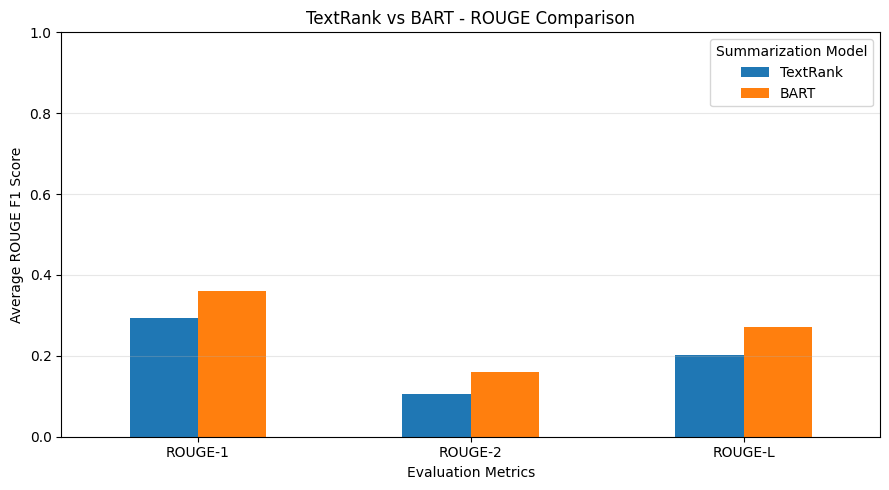

In [ ]:

import matplotlib.pyplot as plt

comparison_plot = comparison.set_index("Metric")

comparison_plot.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("TextRank vs BART - ROUGE Comparison")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Average ROUGE F1 Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Summarization Model")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# Step 9.5: Save results

In [ ]:

results_df.to_csv(
    "summarization_results.csv",
    index=False
)

comparison.to_csv(
    "rouge_comparison.csv",
    index=False
)

print("Evaluation files saved successfully!")


Evaluation files saved successfully!


In [ ]:
# !pip install -q streamlit pyngrok transformers torch nltk scikit-learn networkx

In [ ]:
sample_text = """
Artificial Intelligence is transforming many industries.
Machine learning helps computers learn from data.
Deep learning is used in image recognition and natural language processing.
AI is widely used in healthcare, education, banking and transportation.
"""

print("TextRank Summary:")
print(textrank_summarizer(sample_text))

print("\nBART Summary:")
print(bart_summary(sample_text))

TextRank Summary:
Machine learning helps computers learn from data. Deep learning is used in image recognition and natural language processing. AI is widely used in healthcare, education, banking and transportation.

BART Summary:
 Machine learning helps computers learn from data . Deep learning is used in image recognition and natural language processing . AI is widely used in healthcare, education, banking and transportation .


In [ ]:
%%writefile app.py

import streamlit as st

# Import your summarization functions
from summarizers import textrank_summarizer, bart_summary

# Page configuration
st.set_page_config(
    page_title="AI Text Summarizer",
    page_icon="📝",
    layout="wide"
)

# Application title
st.title("📝 AI-Based Text Summarization System")

st.write(
    "This application generates summaries using "
    "Extractive and Abstractive Summarization techniques."
)

st.markdown("---")

# Text input
st.subheader("Enter Your Article or Research Paper")

input_text = st.text_area(
    "Paste your text here:",
    height=250,
    placeholder="Enter your news article or research paper content..."
)

# Summarization method
st.subheader("Select Summarization Method")

method = st.selectbox(
    "Choose a summarization technique:",
    ["TextRank (Extractive)", "BART (Abstractive)"]
)

# Generate summary
if st.button("Generate Summary"):

    if input_text.strip():

        with st.spinner("Generating summary..."):

            if method == "TextRank (Extractive)":
                summary = textrank_summarizer(input_text)

            else:
                summary = bart_summary(input_text)

        st.success("Summary Generated Successfully!")

        st.subheader("Generated Summary")
        st.write(summary)

        # Display word counts
        original_words = len(input_text.split())
        summary_words = len(summary.split())

        st.markdown("---")
        st.subheader("Summary Statistics")

        col1, col2, col3 = st.columns(3)

        col1.metric("Original Words", original_words)
        col2.metric("Summary Words", summary_words)

        if original_words > 0:
            reduction = (
                (original_words - summary_words) / original_words
            ) * 100
        else:
            reduction = 0

        col3.metric("Length Reduction", f"{reduction:.2f}%")

    else:
        st.warning("Please enter some text before generating a summary.")

st.markdown("---")
st.caption("Developed as an Academic Text Summarization Project")

Overwriting app.py


In [ ]:
%%writefile summarizers.py

import re
import nltk
import numpy as np
import networkx as nx
import torch

from nltk.tokenize import sent_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# Download NLTK resources
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

# Text cleaning
def clean_text(text):
    text = str(text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()


# TextRank Extractive Summarization
def textrank_summarizer(text, num_sentences=3):

    text = clean_text(text)
    sentences = sent_tokenize(text)

    if len(sentences) <= num_sentences:
        return " ".join(sentences)

    vectorizer = TfidfVectorizer(stop_words="english")

    try:
        sentence_vectors = vectorizer.fit_transform(sentences)
    except ValueError:
        return " ".join(sentences[:num_sentences])

    similarity_matrix = (
        sentence_vectors * sentence_vectors.T
    ).toarray()

    np.fill_diagonal(similarity_matrix, 0)

    graph = nx.from_numpy_array(similarity_matrix)

    scores = nx.pagerank(graph, max_iter=100)

    ranked_sentences = sorted(
        scores,
        key=scores.get,
        reverse=True
    )

    selected_indices = sorted(
        ranked_sentences[:num_sentences]
    )

    return " ".join(
        sentences[i] for i in selected_indices
    )


# Load pretrained BART model
model_name = "sshleifer/distilbart-cnn-12-6"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

tokenizer = AutoTokenizer.from_pretrained(model_name)

bart_model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

bart_model.to(device)
bart_model.eval()


# BART Abstractive Summarization
def bart_summary(text):

    text = clean_text(text)

    if not text:
        return ""

    inputs = tokenizer(
        text,
        return_tensors="pt",
        max_length=1024,
        truncation=True
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():

        summary_ids = bart_model.generate(
            inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            max_new_tokens=100,
            min_length=25,
            num_beams=4,
            early_stopping=True,
            no_repeat_ngram_size=3
        )

    return tokenizer.decode(
        summary_ids[0],
        skip_special_tokens=True
    )

Overwriting summarizers.py


In [ ]:
# !pip install -q pyngrok

In [ ]:
from pyngrok import ngrok

# ngrok.set_auth_token("3LSuyLeCq7wC3hO00x1TqMOPKTk_3SAD2Htbkckt5QP9fpFTi")

In [ ]:
!streamlit run app.py --server.port 8501 --server.address 0.0.0.0 &



2026-10-31 16:43:47.788 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.124.192.234:8501

  Stopping...


In [ ]:
from pyngrok import ngrok

public_url = ngrok.connect(8501)

print("Your Streamlit Application:")
print(public_url)

Your Streamlit Application:
NgrokTunnel: "https://tidbit-oblong-spent.ngrok-free.dev" -> "http://localhost:8501"


In [ ]:
!curl -I http://127.0.0.1:8501

curl: (7) Failed to connect to 127.0.0.1 port 8501 after 0 ms: Couldn't connect to server


In [ ]:
import os

print("app.py exists:", os.path.exists("app.py"))
print("summarizers.py exists:", os.path.exists("summarizers.py"))

app.py exists: True
summarizers.py exists: True


In [ ]:
import subprocess
import time

streamlit_process = subprocess.Popen(
    [
        "streamlit",
        "run",
        "app.py",
        "--server.port=8501",
        "--server.address=0.0.0.0",
        "--server.headless=true"
    ],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

time.sleep(15)

print("Process status:", streamlit_process.poll())

if streamlit_process.poll() is not None:
    print("Streamlit startup error:")
    print(streamlit_process.stdout.read())
else:
    print("Streamlit process is running!")

Process status: None
Streamlit process is running!
